In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from scipy.stats import gamma
import numpy as np
import warnings
warnings.filterwarnings("ignore")

plt.rcParams.update({
    'font.family': 'Arial',
    'font.size': 6,
    'axes.titlesize': 6,
    'axes.labelsize': 6,
    'xtick.labelsize': 6,
    'ytick.labelsize': 6,
    'legend.fontsize': 6,
    'figure.titlesize': 6,
    'figure.dpi': 200,
    'axes.linewidth': 0.7,
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
    'mathtext.fontset': 'custom',
    'mathtext.rm': 'Arial',
    'mathtext.it': 'Arial:italic',
    'mathtext.bf': 'Arial:bold',
})

Fig. 6e

In [2]:
# Function for reading SFS file
def read_sfs_file(file):

    with open(file, "r") as f:
        f.readline()
        sfs_data = [float(prop) for prop in f.readline().strip().split()]

    return sfs_data


def get_prop(file):

    sfs_data = read_sfs_file(file)
    sfs_data = sfs_data[1:]
    total = sum(sfs_data)

    singleton_prop = sfs_data[0] / total
    doubleton_prop = sfs_data[1] / total
    tripleton_prop = sfs_data[2] / total
    other_prop = sum(sfs_data[3:]) / total

    return {
        "singleton prop": singleton_prop,
        "doubleton prop": doubleton_prop,
        "tripleton prop": tripleton_prop,
        "4+ prop": other_prop,
    }

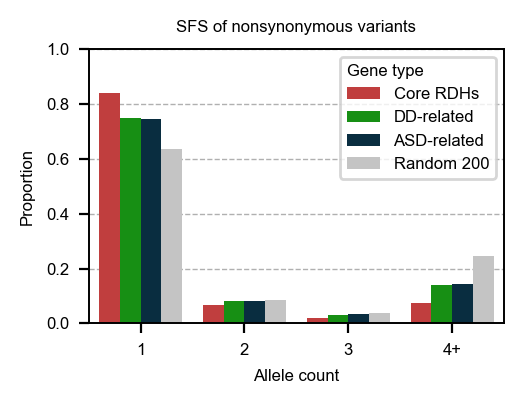

In [3]:
# Plot nonsynonymous SFSs
gene_prop_dict = {}

for gene_type in ["cRDHGs", "DD", "ASD", "R200"]:
    gene_prop_dict[gene_type] = get_prop(
        f"data/nonsyn_SFSs_DFEs/gnomadv4.nfe.nonsynonymous.folded.NS2000.{gene_type}.fs"
    )

gene_prop_df = pd.DataFrame(gene_prop_dict)
# Convert to long format
gene_prop_df = gene_prop_df.reset_index().melt(
    id_vars="index", var_name="Gene Type", value_name="Proportion"
)
gene_prop_df = gene_prop_df.rename(columns={"index": "Frequency Class"})

gene_prop_df["Frequency Class"] = gene_prop_df["Frequency Class"].map(
    {
        "singleton prop": "1",
        "doubleton prop": "2",
        "tripleton prop": "3",
        "4+ prop": "4+",
    }
)
gene_prop_df["Gene Type"] = gene_prop_df["Gene Type"].map(
    {
        "cRDHGs": "Core RDHs",
        "DD": "DD-related",
        "ASD": "ASD-related",
        "R200": "Random 200",
    }
)

fig, ax = plt.subplots(figsize=(2.6, 2))

sns.barplot(
    data=gene_prop_df,
    x="Frequency Class",
    y="Proportion",
    hue="Gene Type",
    zorder=2,
    ax=ax,
    palette={
        "Core RDHs": "#D62828",
        "DD-related": "#03A300",
        "ASD-related": "#003049",
        "Random 200": "#C4C4C4",
    },
)
ax.set_ylim(0, 1)
ax.set_xlabel("Allele count")
ax.set_ylabel("Proportion")
ax.set_title("SFS of nonsynonymous variants")

ax.grid(axis="y", linestyle="--", linewidth=0.5, zorder=1)
ax.legend(
    title="Gene type",
    alignment="left",
    loc="upper right",
    ncols=1,
)

plt.tight_layout()

Fig. 6f

In [4]:
# Plot DFEs
gnomAD_Na = 14230
gene_name = [
    "cRDHGs",
    "DD",
    "ASD",
    "R200",
]

def get_gamma_bin(alpha, beta, bins):

    distrib = gamma(a=alpha, scale=beta)
    out = []
    for lo, hi in zip(bins[:-1], bins[1:]):
        out.append(distrib.cdf(hi) - distrib.cdf(lo))
    return np.array(out)

s_bins = np.array([0, 1e-5, 1e-4, 1e-3, 1e-2, np.inf])
g_bins = 2 * s_bins * gnomAD_Na
s_bin_name = [
    r"0–$10^{-5}$",
    r"$10^{-5}$–$10^{-4}$",
    r"$10^{-4}$–$10^{-3}$",
    r"$10^{-3}$–$10^{-2}$",
    r"$>0.01$",
]

gene_bin_propor = {}
gene_bin_ci = {}
fit_columns = ["ll", "alpha", "beta", "theta"]

for gn in gene_name:

    fit_file = f"data/nonsyn_SFSs_DFEs/gnomadv4.nfe.folded.NS2000.{gn}_1d_dfe_fits.result"
    fit_df = pd.read_csv(fit_file, sep="\t", float_precision="round_trip")

    # Choose fit using full data as central point
    full_data_fits = fit_df[fit_df["replicate"] == -1]
    best_fit = full_data_fits.loc[full_data_fits["ll"].idxmax()]
    gene_bin_propor[gn] = get_gamma_bin(best_fit["alpha"], best_fit["beta"], g_bins)

    # Get bootstrap interval
    bootstrap_fits = fit_df[fit_df["replicate"] >= 0].sort_values("replicate")
    valid_fits = bootstrap_fits.dropna(subset=fit_columns)
    bootstrap_propor = np.array([
        get_gamma_bin(fit.alpha, fit.beta, g_bins)
        for fit in valid_fits.itertuples(index=False)
    ])
    gene_bin_ci[gn] = np.percentile(bootstrap_propor, [2.5, 97.5], axis=0)
    print(f"{gn}: {len(valid_fits)}/{len(bootstrap_fits)} valid bootstrap replicates")

cRDHGs: 100/100 valid bootstrap replicates
DD: 100/100 valid bootstrap replicates
ASD: 100/100 valid bootstrap replicates
R200: 99/100 valid bootstrap replicates


findfont: Font family ['cursive'] not found. Falling back to DejaVu Sans.
findfont: Generic family 'cursive' not found because none of the following families were found: Apple Chancery, Textile, Zapf Chancery, Sand, Script MT, Felipa, Comic Neue, Comic Sans MS, cursive


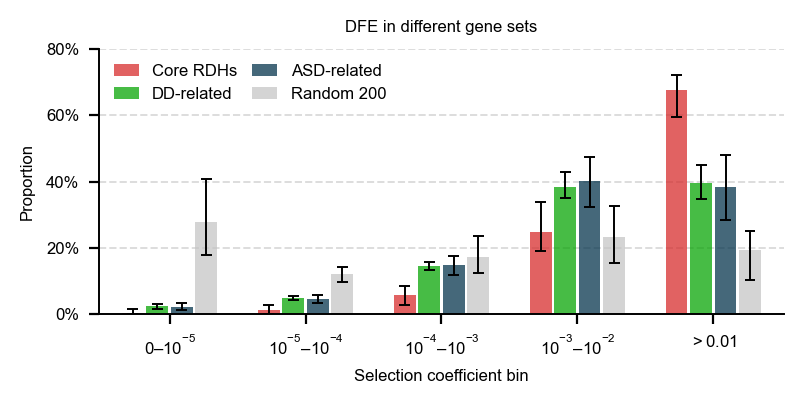

In [5]:
# Plot DFE proportions by selection-coefficient bin.
gene_labels = ["Core RDHs", "DD-related", "ASD-related", "Random 200"]
colors = ["#D62828", "#03A300", "#003049", "#C4C4C4"]

x = np.arange(len(s_bin_name))
spacing = 0.18

fig, ax = plt.subplots(figsize=(4, 2))
for i, (gn, label, color) in enumerate(zip(gene_name, gene_labels, colors)):
    positions = x + (i - 1.5) * spacing
    ax.bar(
        positions,
        gene_bin_propor[gn],
        width=0.16,
        color=color,
        alpha=0.73,
        label=label,
        zorder=2,
    )
    low, high = gene_bin_ci[gn]
    ax.vlines(positions, low, high, color="black", linewidth=0.7, zorder=3)
    for endpoint in (low, high):
        ax.hlines(
            endpoint,
            positions - 0.04,
            positions + 0.04,
            color="black",
            linewidth=0.7,
            zorder=3,
        )

ax.set_xticks(x, s_bin_name)
ax.set_xlim(-0.52, len(x) - 0.48)
ax.set_yticks(np.linspace(0, 0.8, 5))
ax.set_ylim(0, 0.8)

ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
ax.set_xlabel("Selection coefficient bin")
ax.set_ylabel("Proportion")
ax.set_title("DFE in different gene sets")

ax.grid(axis="y", linestyle="--", linewidth=0.7, color="#DDDDDD", zorder=1)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="upper left", ncols=2, frameon=False, handlelength=1.5, columnspacing=0.9)

plt.tight_layout()

In [7]:
gene_bin_ci, gene_bin_propor

({'cRDHGs': array([[1.50867385e-04, 2.05533377e-03, 2.90912433e-02, 1.90561463e-01,
          5.93466921e-01],
         [1.58241753e-02, 2.89518690e-02, 8.43445019e-02, 3.39930133e-01,
          7.22379883e-01]]),
  'DD': array([[0.0172046 , 0.04194763, 0.13302447, 0.34990799, 0.34715418],
         [0.03195943, 0.05680412, 0.15784135, 0.43019018, 0.44956707]]),
  'ASD': array([[0.0119458 , 0.03530356, 0.11895808, 0.32426701, 0.28377319],
         [0.03420955, 0.05902469, 0.17670866, 0.47346195, 0.47913463]]),
  'R200': array([[0.17797782, 0.09819015, 0.1237541 , 0.15397296, 0.10452005],
         [0.40783066, 0.14191411, 0.23495815, 0.32570504, 0.25220613]])},
 {'cRDHGs': array([0.00376643, 0.01321582, 0.05917736, 0.24786718, 0.67597321]),
  'DD': array([0.02440062, 0.04916151, 0.14626375, 0.38425273, 0.39592139]),
  'ASD': array([0.02148457, 0.04697542, 0.1474317 , 0.40124442, 0.38286389]),
  'R200': array([0.27780955, 0.12170942, 0.17383154, 0.23313026, 0.19351922])})